In [1]:
import sys, platform, torch
print("Python path:   ", sys.executable)
print("Python version:", sys.version.split()[0])
print("Machine:       ", platform.machine())
print("torch:         ", torch.__version__)
print("MPS available: ", torch.backends.mps.is_available())

Python path:    /Users/xiaoyiwen/miniforge3/envs/dfpi/bin/python
Python version: 3.11.17
Machine:        arm64
torch:          2.14.1
MPS available:  True


# Import tools

In [3]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm

# Main script for aic

## Get images through API

In [65]:
DATASET_NAME = "aic_still_life"

ROOT = Path.cwd()
DATA_DIR = ROOT / "workshop2_data"
CHECKPOINTS_DIR = DATA_DIR / "checkpoints" # model parameters
DATASET_DIR = DATA_DIR / DATASET_NAME     # 每组自己的文件夹【改动】
IMAGES_DIR = DATASET_DIR / "images"  # downloaded images
OUTPUTS_DIR = DATASET_DIR / "outputs"
MASKS_DIR = OUTPUTS_DIR / "sam_masks"

for folder in [DATA_DIR, CHECKPOINTS_DIR, DATASET_DIR, IMAGES_DIR, OUTPUTS_DIR, MASKS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE="mps"

print("Working directory:",ROOT.resolve())
print("Dataset folder:",DATASET_DIR.resolve())
print("Model device:",DEVICE)

Working directory: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis
Dataset folder: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life
Model device: mps


In [66]:
search_url="https://api.artic.edu/api/v1/artworks/search"

session=requests.Session()
session.headers.update({
    "Accept":"application/json",
    "AIC-User-Agent":"UCL-dfpi-student-workshop/1.0 (ucbv728@ucl.ac.uk)",
    
})

query="still life"
max_images=300
page_size=50

#create lists
records=[]
seen_ids=set()
skipped_no_image=0
failures=[]

#create progress
page=1
progress=tqdm(total=max_images,desc="Downloading",unit="image")

while len(records)<max_images:
    if len(failures) >= 10:
        print("Too many failures, stopping. Check the failures list.")
        break
    
    params={
        "q":query,
        "query[term][is_public_domain]":"true",
        "fields":"id,title,artist_display,date_display,image_id,artwork_type_title",
        "limit":page_size,
        "page":page,
    }
    response=session.get(search_url,params=params,timeout=30)
    response.raise_for_status()
    page_data=response.json()
    page_records=page_data["data"]
    iiif_url=page_data["config"]["iiif_url"]

    if not page_records:
        print("No more results.")
        break

    for record in page_records:
        if len(records)>=max_images:
            break
        artwork_id=record["id"]
        if artwork_id in seen_ids:
            continue
        seen_ids.add(artwork_id)

        image_id=record.get("image_id")
        if not image_id:
            skipped_no_image+=1
            continue

        image_url=f"{iiif_url}/{image_id}/full/843,/0/default.jpg"
        local_path=IMAGES_DIR/f"aic_{artwork_id}.jpg"

        try:
            if not local_path.exists():
                image_response=session.get(image_url,timeout=60)
                image_response.raise_for_status()
                local_path.write_bytes(image_response.content)
                time.sleep(1)

            with Image.open(local_path) as tst_image:
                tst_image.verify()
        except Exception as exc:
            failures.append((artwork_id,str(exc)))
            local_path.unlink(missing_ok=True)
            continue

        records.append({
            "id": f"aic_{artwork_id}",
            "artwork_id": artwork_id,
            "title": record.get("title") or "Untitled",
            "artist": record.get("artist_display") or "Unknown",
            "date": record.get("date_display") or "",
            "artwork_type": record.get("artwork_type_title") or "",
            "image_id": image_id,
            "image_url": image_url,
            "source_url": f"https://www.artic.edu/artworks/{artwork_id}",
            "license": "Public domain",
            "query": query,
            "local_path": str(local_path.resolve()),
        })
        progress.update(1)

    page+=1

progress.close()

print("Downloaded:", len(records))
print("Pages requested:", page - 1)
print("Skipped (no image):", skipped_no_image)
print("Failed:", len(failures))
for failed_id, reason in failures[:3]:
    print("  ", failed_id, reason)

Downloading: 100%|████████████████████████| 300/300 [05:07<00:00,  1.02s/image]

Downloaded: 300
Pages requested: 7
Skipped (no image): 2
Failed: 5
   52757 403 Client Error: Forbidden for url: https://www.artic.edu/iiif/2/2f30b7cc-6371-f801-ff76-4a2f126b89e9/full/843,/0/default.jpg
   77895 403 Client Error: Forbidden for url: https://www.artic.edu/iiif/2/ddb7cdac-8238-a260-427a-6590e827d923/full/843,/0/default.jpg
   122445 403 Client Error: Forbidden for url: https://www.artic.edu/iiif/2/04d3a5ee-7ef7-9555-7e41-0708710c07d6/full/843,/0/default.jpg


# Show images

In [67]:
def show_image_grid(rows, image_col="local_path", title_col="title", columns=5, max_items=15):
    # Display images from a DataFrame or list of dictionaries.
    if isinstance(rows, pd.DataFrame):
        records = rows.head(max_items).to_dict("records")
    else:
        records = list(rows)[:max_items]

    if not records:
        print("No images to display.")
        return

    n = len(records)
    rows_n = int(np.ceil(n / columns))
    fig, axes = plt.subplots(rows_n, columns, figsize=(3.2 * columns, 3.4 * rows_n))
    axes = np.atleast_1d(axes).ravel()

    for ax, record in zip(axes, records):
        try:
            image = Image.open(record[image_col]).convert("RGB")
            ax.imshow(image)
        except Exception as exc:
            ax.text(0.5, 0.5, f"Could not load image\n{exc}", ha="center", va="center")
        ax.set_title(str(record.get(title_col, ""))[:55], fontsize=9)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

Rows in manifest: 300
Saved to: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/manifest.csv

Artwork types:
artwork_type
Painting                   135
Print                      105
Photograph                  24
Drawing and Watercolor      17
Sculpture                    7
Textile                      5
Medals                       1
Vessel                       1
Architectural fragment       1
Decorative Arts              1
Ceramics                     1
Religious/Ritual Object      1
Metalwork                    1
Name: count, dtype: int64


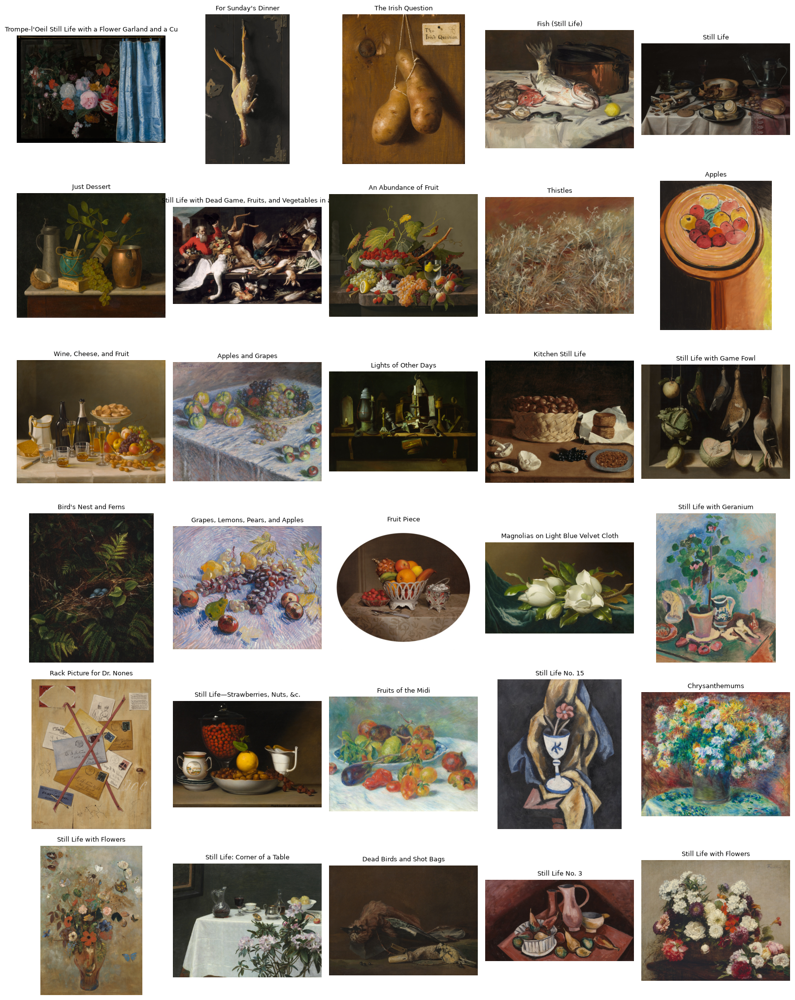

In [68]:
manifest = pd.DataFrame(records)
manifest_path = DATASET_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8")

print("Rows in manifest:", len(manifest))
print("Saved to:", manifest_path)
print()
print("Artwork types:")
print(manifest["artwork_type"].value_counts())

show_image_grid(manifest, columns=5, max_items=30)

# CLIP

In [69]:
#read manifest from my local harddisk
manifest = pd.read_csv(DATASET_DIR / "manifest.csv")
print("Rows:", len(manifest))
manifest.head(3)

Rows: 300


,id,artwork_id,title,artist,date,artwork_type,image_id,image_url,source_url,license,query,local_path
0,aic_66042,66042,Trompe-l'Oeil Still Life with a Flower Garland...,"Adriaen van der Spelt (Dutch, 1630–1673)\nFran...",1658,Painting,4a04138f-43d8-cd9f-5ac4-478cd8828210,https://www.artic.edu/iiif/2/4a04138f-43d8-cd9...,https://www.artic.edu/artworks/66042,Public domain,still life,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
1,aic_111377,111377,For Sunday's Dinner,"William Michael Harnett (American, born Irelan...",1888,Painting,3cea045a-92d6-36cf-1508-2c99ea740218,https://www.artic.edu/iiif/2/3cea045a-92d6-36c...,https://www.artic.edu/artworks/111377,Public domain,still life,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
2,aic_181777,181777,The Irish Question,"De Scott Evans\nAmerican, 1847–1898",1880s,Painting,6754947f-4ccf-b3ff-41ee-45b738534769,https://www.artic.edu/iiif/2/6754947f-4ccf-b3f...,https://www.artic.edu/artworks/181777,Public domain,still life,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...


In [42]:
#download CLIP model
from huggingface_hub import snapshot_download

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
CLIP_CHECKPOINT_DIR = CHECKPOINTS_DIR / "clip-vit-base-patch32"

snapshot_download(
    repo_id=CLIP_MODEL_ID,
    local_dir=CLIP_CHECKPOINT_DIR,
    ignore_patterns=[
        "*.msgpack", "*.h5", "*.onnx", "*.tflite",
        "flax_model.*", "tf_model.*",
    ],
)

print("CLIP checkpoint at:", CLIP_CHECKPOINT_DIR.resolve())

Fetching 10 files: 100%|███████████████████████| 10/10 [00:16<00:00,  1.67s/it]

CLIP checkpoint at: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/checkpoints/clip-vit-base-patch32


In [43]:
#load CLIP into memory
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained(CLIP_CHECKPOINT_DIR).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_CHECKPOINT_DIR)

print("Loaded:", CLIP_MODEL_ID)
print("Device:", DEVICE)

Loading weights: 100%|████████████████████| 398/398 [00:00<00:00, 61811.12it/s]


Loaded: openai/clip-vit-base-patch32
Device: mps


In [70]:
if manifest.empty:
    raise ValueError("The manifest is empty. Run the API section or add local images first.")

image_paths = manifest["local_path"].tolist()
batch_size = 16 if DEVICE == "cuda" else 8
feature_batches = []

for start in tqdm(range(0, len(image_paths), batch_size), desc="CLIP image embeddings"):
    batch_paths = image_paths[start:start + batch_size]
    batch_images = [Image.open(path).convert("RGB") for path in batch_paths]
    inputs = clip_processor(images=batch_images, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        feature_output = clip_model.get_image_features(**inputs)
        # Transformers 5 returns a structured output; older versions return a tensor.
        features = (
            feature_output.pooler_output
            if hasattr(feature_output, "pooler_output")
            else feature_output
        )
        features = features / features.norm(dim=-1, keepdim=True)

    feature_batches.append(features.cpu().float().numpy())

image_embeddings = np.vstack(feature_batches)
embeddings_path = OUTPUTS_DIR / "clip_image_embeddings.npy"
np.save(embeddings_path, image_embeddings)

print("Embedding matrix:", image_embeddings.shape)
print("Saved:", embeddings_path.resolve())

CLIP image embeddings: 100%|███████████████████| 38/38 [00:04<00:00,  8.88it/s]

Embedding matrix: (300, 512)
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/outputs/clip_image_embeddings.npy


## Identify images by description

,title,artist,date,clip_similarity
18,Magnolias on Light Blue Velvet Cloth,"Martin Johnson Heade (American, 1819–1904)",1885–95,0.221308
25,Still Life with Flowers,"Odilon Redon (French, 1840–1916)",1905,0.211948
96,The Song of the Lark,"Jules Breton (French, 1827–1906)",1884,0.211847
198,The Marsh,"Constant Troyon (French, 1810–1865)",1840,0.211412
243,"Landscape with Sheep, Picardy","Harry Thompson (English, died 1901)",Late 19th century,0.209970
280,Souvenir of Italy,"Jean-Baptiste-Camille Corot (French, 1796–1875)",1855–60,0.209744
138,"Charing Cross Bridge, London","Claude Monet (French, 1840–1926)",1901,0.209640
119,"Waterloo Bridge, Gray Weather","Claude Monet (French, 1840–1926)",1900,0.208917
54,Flowers: Poppies and Daisies,"Odilon Redon (French, 1840–1916)",c. 1867,0.208867
175,Triptych of the Virgin and Child with Scenes f...,Italian; probably Venice,c. 1320,0.208739


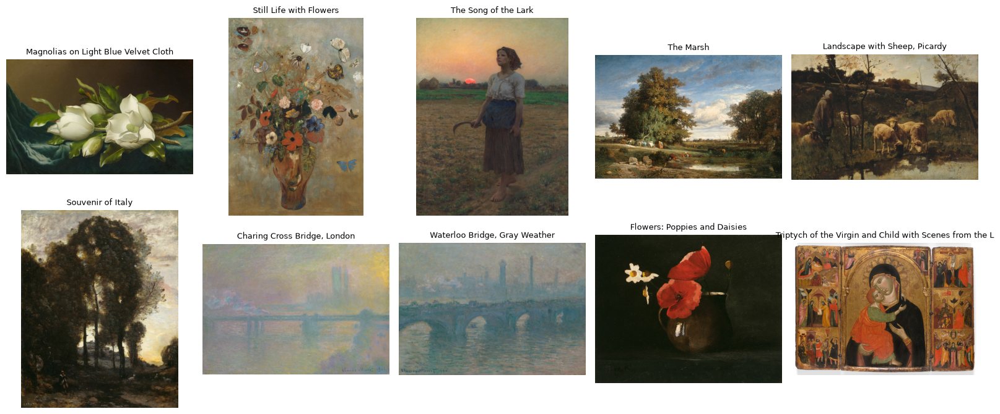

,title,artist,date,clip_similarity
1,For Sunday's Dinner,"William Michael Harnett (American, born Irelan...",1888,0.202997
40,Calf's Head and Ox Tongue,"Gustave Caillebotte (French, 1848–1894)",c. 1882,0.200568
94,Life Study (Study of an Egyptian Girl),"John Singer Sargent (American, 1856–1925)",1891,0.196572
87,Life-Size Black Bass,"Winslow Homer\nAmerican, 1836-1910",1904,0.195136
98,Woman at Her Toilette,"Edgar Degas\nFrench, 1834-1917",1900/05,0.194123
263,"Hotei, from the series ""The Seven Gods of Good...","Suzuki Harunobu 鈴木 春信\nJapanese, 1725 (?)-1770",c. 1769,0.193204
202,Portrait of a Gentleman,"Ridolfo Ghirlandaio (Italian, 1483–1561)",c. 1505,0.192584
271,"Hercules Killing the Lernean Hydra, from Scene...","Gabriel Salmon\nFrench, active 1504-1542",c. 1528,0.192131
135,Evening Snow on a Floss Shaper (Nurioke no bos...,"Suzuki Harunobu 鈴木 春信 \nJapanese, 1725 (?)-1770",c. 1766,0.191984
86,Life Cast of the Hands and Face of Abraham Lin...,"Leonard Wells Volk (American, 1828–1895)",Cast in plaster 1860; cast in bronze by 1888,0.191908


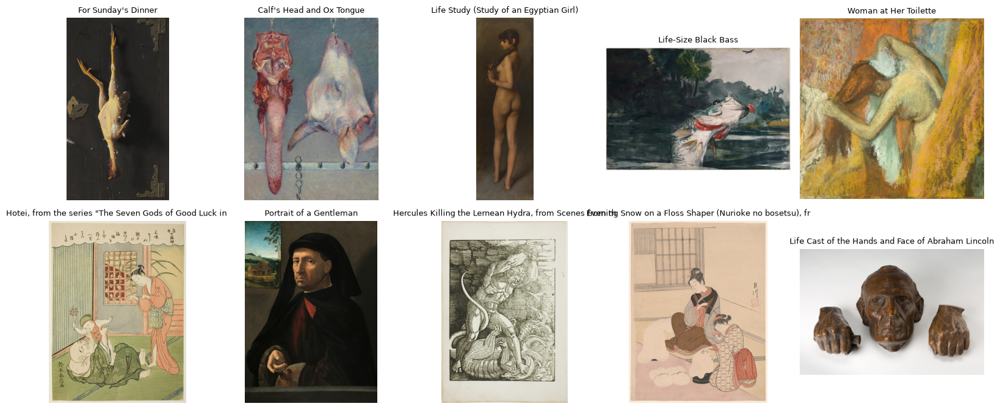

In [71]:
def search_images_with_text(query, top_k=8):
    text_inputs = clip_processor(text=[query], return_tensors="pt", padding=True)
    text_inputs = {key: value.to(DEVICE) for key, value in text_inputs.items()}

    with torch.inference_mode():
        text_feature_output = clip_model.get_text_features(**text_inputs)
        # Use the projected tensor from either the new or older API.
        text_features = (
            text_feature_output.pooler_output
            if hasattr(text_feature_output, "pooler_output")
            else text_feature_output
        )
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    similarities = image_embeddings @ text_features.cpu().float().numpy()[0]
    order = np.argsort(similarities)[::-1][:top_k]
    results = manifest.iloc[order].copy()
    results["clip_similarity"] = similarities[order]
    return results


#describe something you want to find in plain language.
TEXT_QUERY1 = "beautiful"
text_results1 = search_images_with_text(TEXT_QUERY1, top_k=10)
display(text_results1[["title", "artist", "date", "clip_similarity"]])
show_image_grid(text_results1, columns=5, max_items=10)

TEXT_QUERY2 = "ugly"
text_results2 = search_images_with_text(TEXT_QUERY2, top_k=10)
display(text_results2[["title", "artist", "date", "clip_similarity"]])
show_image_grid(text_results2, columns=5, max_items=10)

## Find similar images

Selected image: The Irish Question


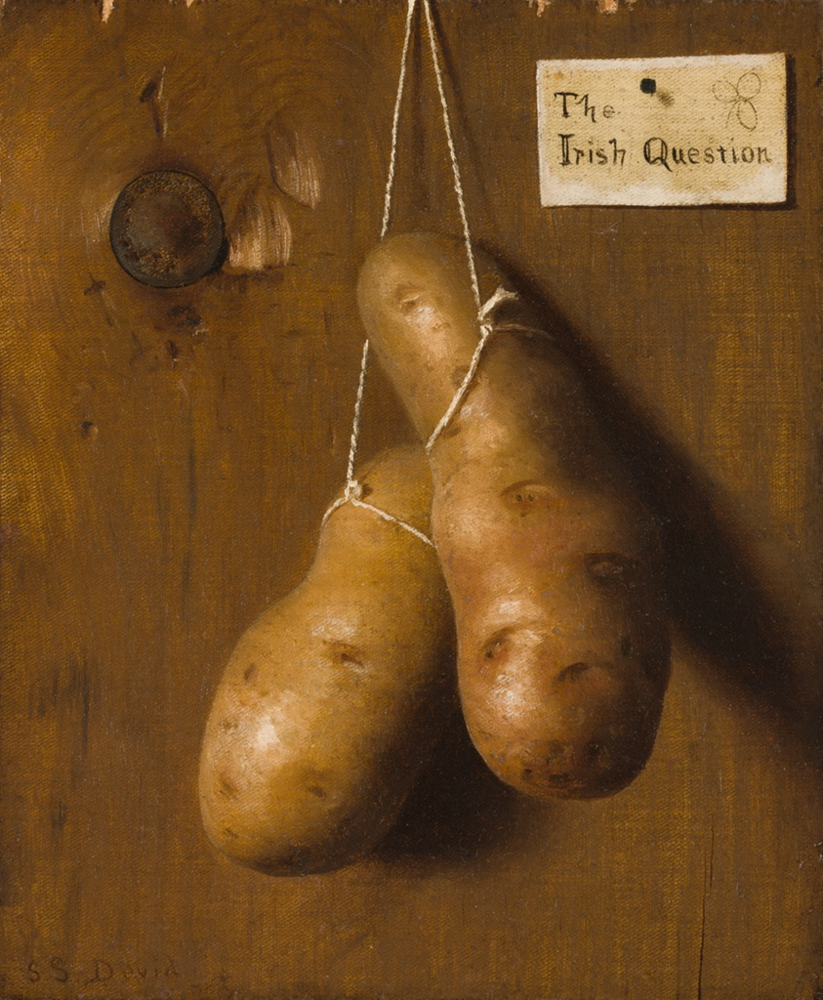

,title,artist,date,clip_similarity
14,Still Life with Game Fowl,"Juan Sánchez Cotán (Spanish, 1560–1627)",c. 1600–3,0.759336
7,An Abundance of Fruit,"Severin Roesen\nAmerican, born Germany, 1815/1...",c. 1860,0.734767
32,Still Life with a Basket of Fruit and a Bunch ...,"Louise Moillon (French, 1610–1696)",1630,0.733193
13,Kitchen Still Life,"Attributed to Paolo Antonio Barbieri (Italian,...",c. 1640,0.730997
45,Flowers and Fruit in a Porcelain Bowl,"Juan de Zurbarán (Spanish, 1620–1649)",c. 1645,0.729819
21,"Still Life—Strawberries, Nuts, &c.","Raphaelle Peale (American, 1774–1825)",1822,0.727437
3,Fish (Still Life),"Édouard Manet (French, 1832–1883)",1864,0.724545
4,Still Life,"Pieter Claesz (Dutch, 1596/97–1660)",c. 1625,0.723366
22,Fruits of the Midi,"Pierre-Auguste Renoir (French, 1841–1919)",1881,0.722017
62,Still Life with Grapes and Flowers,"Mélanie de Comoléra (French, 1789-1854)",c. 1827,0.721843


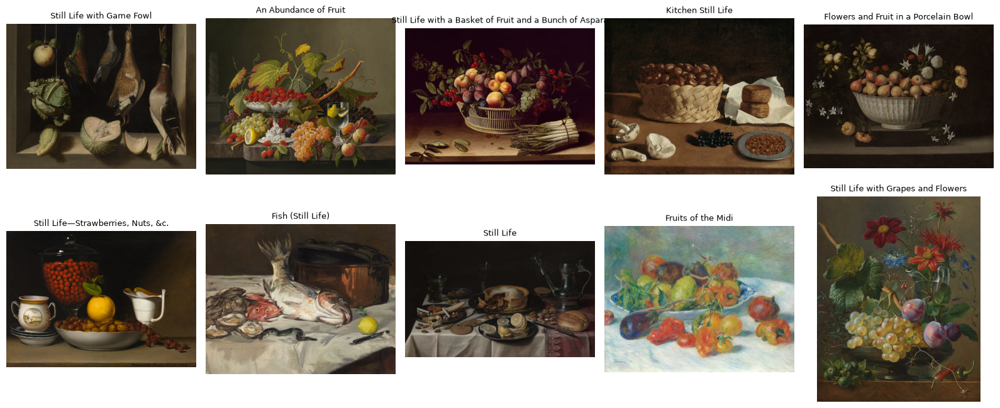

In [72]:
def nearest_images(image_index, top_k=8):
    similarities = image_embeddings @ image_embeddings[image_index]
    order = np.argsort(similarities)[::-1]
    order = order[order != image_index][:top_k]
    results = manifest.iloc[order].copy()
    results["clip_similarity"] = similarities[order]
    return results


# STUDENT CHOICE 5: choose a row number from 0 to len(manifest) - 1.
SELECTED_IMAGE_INDEX = 2 # replace with any row
print("Selected image:", manifest.iloc[SELECTED_IMAGE_INDEX]["title"])
display(Image.open(manifest.iloc[SELECTED_IMAGE_INDEX]["local_path"]).convert("RGB"))

neighbour_results = nearest_images(SELECTED_IMAGE_INDEX, top_k=10)
display(neighbour_results[["title", "artist", "date", "clip_similarity"]])
show_image_grid(neighbour_results, columns=5, max_items=10)

## PCA

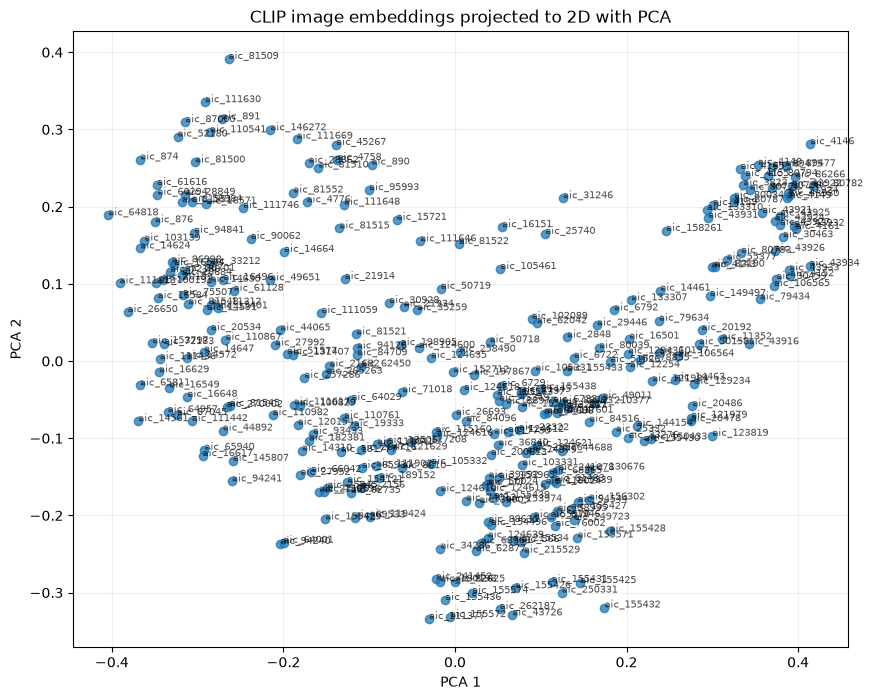

In [73]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
embedding_2d = pca.fit_transform(image_embeddings)

manifest["clip_x"] = embedding_2d[:, 0]
manifest["clip_y"] = embedding_2d[:, 1]

plt.figure(figsize=(10, 8))
plt.scatter(manifest["clip_x"], manifest["clip_y"], alpha=0.75)
for _, row in manifest.iterrows():
    plt.annotate(str(row["id"]), (row["clip_x"], row["clip_y"]), fontsize=7, alpha=0.7)
plt.title("CLIP image embeddings projected to 2D with PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(alpha=0.2)
plt.show()

# YOLO

In [74]:
from ultralytics import YOLO, settings

settings.update({
    "weights_dir": str(CHECKPOINTS_DIR.resolve()),
    "runs_dir": str((OUTPUTS_DIR / "runs").resolve()),
})

YOLO_CHECKPOINT = "yolo26n.pt"
yolo_model = YOLO(YOLO_CHECKPOINT)  # downloads the checkpoint if it is absent

print("YOLO checkpoint ready:", YOLO_CHECKPOINT)
print("Ultralytics weights directory:", settings["weights_dir"])

YOLO checkpoint ready: yolo26n.pt
Ultralytics weights directory: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/checkpoints


In [75]:
path_to_id = {
    str(Path(row.local_path).resolve()).lower(): row.id
    for row in manifest.itertuples()
}

detection_rows = []
prediction_stream = yolo_model.predict(
    source=manifest["local_path"].tolist(),
    stream=True,
    conf=0.25,
    imgsz=640,
    device=DEVICE,
    verbose=False,
)

for result in tqdm(prediction_stream, total=len(manifest), desc="YOLO detections"):
    resolved_path = str(Path(result.path).resolve()).lower()
    image_id = path_to_id.get(resolved_path, Path(result.path).stem)

    if result.boxes is None or len(result.boxes) == 0:
        continue

    boxes_xyxy = result.boxes.xyxy.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()
    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    for box, confidence, class_id in zip(boxes_xyxy, confidences, class_ids):
        x1, y1, x2, y2 = box.tolist()
        detection_rows.append({
            "image_id": image_id,
            "class_id": class_id,
            "class_name": result.names[class_id],
            "confidence": float(confidence),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),
            "width": float(x2 - x1),
            "height": float(y2 - y1),
        })

detections = pd.DataFrame(detection_rows)
detections_path = OUTPUTS_DIR / "detections.csv"
detections.to_csv(detections_path, index=False)

print(f"Detected {len(detections)} objects across {len(manifest)} images.")
print("Saved:", detections_path.resolve())
detections.head(10)

YOLO detections: 100%|███████████████████████| 300/300 [00:10<00:00, 29.38it/s]


Detected 672 objects across 300 images.
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/outputs/detections.csv


,image_id,class_id,class_name,confidence,x1,y1,x2,y2,width,height
0,aic_181777,54,donut,0.500880,201.921127,510.196472,469.811768,898.355286,267.890640,388.158813
1,aic_44892,14,bird,0.821280,216.293579,28.923025,652.984802,464.600464,436.691223,435.677439
2,aic_44892,14,bird,0.364541,0.000000,280.344604,269.423920,510.338867,269.423920,229.994263
3,aic_44892,49,orange,0.324098,672.633301,410.025665,768.282410,493.198669,95.649109,83.173004
4,aic_21682,40,wine glass,0.782282,318.541718,93.170753,379.137360,229.454514,60.595642,136.283760
5,aic_21682,41,cup,0.698412,81.922951,144.884354,189.318527,270.638458,107.395576,125.754105
6,aic_21682,48,sandwich,0.675224,347.198059,194.820297,550.091858,309.379059,202.893799,114.558762
7,aic_21682,45,bowl,0.397979,178.607864,206.443558,300.810242,256.625122,122.202377,50.181564
8,aic_44065,75,vase,0.784205,535.635803,293.008575,711.541748,544.801575,175.905945,251.792999
9,aic_44065,75,vase,0.376438,106.213982,182.643921,258.327576,510.811676,152.113594,328.167755


Selected image: Fruit Piece


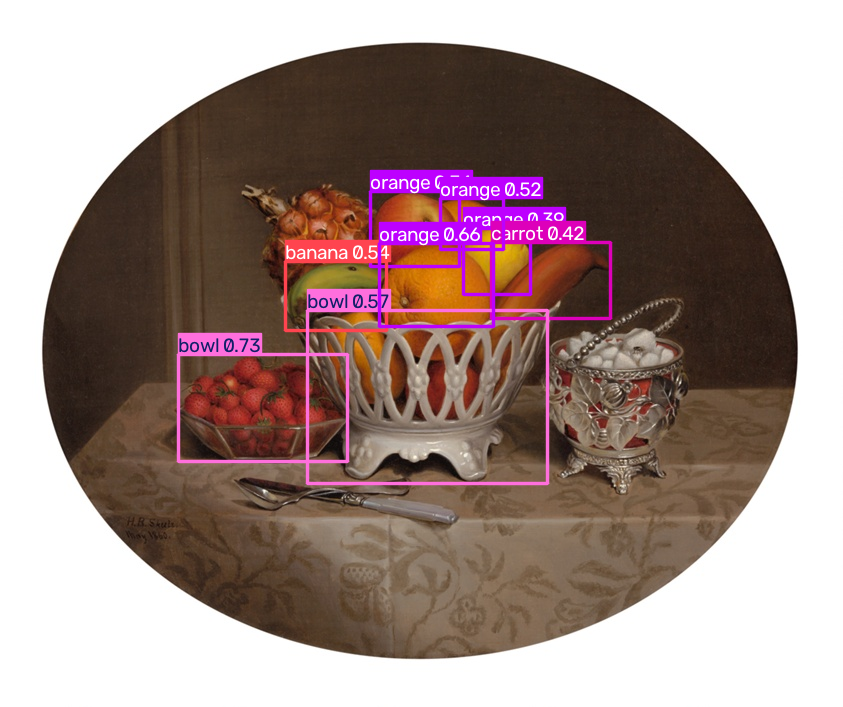

In [77]:
# STUDENT CHOICE 6: choose which image YOLO should demonstrate.
DEMO_IMAGE_INDEX = 17
demo_image_path = manifest.iloc[DEMO_IMAGE_INDEX]["local_path"]
print("Selected image:", manifest.iloc[DEMO_IMAGE_INDEX]["title"])
demo_result = yolo_model.predict(
    demo_image_path,
    conf=0.25,
    imgsz=640,
    device=DEVICE,
    verbose=False,
)[0]

# Ultralytics plotting returns BGR; reverse channels for PIL/RGB display.
annotated_rgb = demo_result.plot()[..., ::-1]
display(Image.fromarray(annotated_rgb))

In [78]:
if detections.empty:
    detection_counts = pd.DataFrame(index=manifest["id"])
else:
    detection_counts = (
        detections.groupby(["image_id", "class_name"])
        .size()
        .unstack(fill_value=0)
        .add_prefix("detected_")
    )

manifest_enriched = manifest.set_index("id").join(detection_counts).reset_index()
manifest_enriched.to_csv(OUTPUTS_DIR / "manifest_enriched.csv", index=False)

detected_image_count = detections["image_id"].nunique() if not detections.empty else 0
coverage = detected_image_count / len(manifest) if len(manifest) else 0
print(f"YOLO found at least one known COCO object in {detected_image_count}/{len(manifest)} images ({coverage:.1%}).")
print("Inspect the labels visually. A high confidence score does not make an irrelevant label correct.")
display(detection_counts.sum().sort_values(ascending=False).head(15).to_frame("total"))
manifest_enriched.head()

YOLO found at least one known COCO object in 213/300 images (71.0%).
Inspect the labels visually. A high confidence score does not make an irrelevant label correct.


,total
class_name,
detected_person,402
detected_horse,33
detected_sheep,28
detected_vase,25
detected_bowl,20
detected_orange,16
detected_umbrella,13
detected_cow,11
detected_cup,10


,id,artwork_id,title,artist,date,artwork_type,image_id,image_url,source_url,license,...,detected_spoon,detected_sports ball,detected_surfboard,detected_teddy bear,detected_tie,detected_truck,detected_tv,detected_umbrella,detected_vase,detected_wine glass
0,aic_66042,66042,Trompe-l'Oeil Still Life with a Flower Garland...,"Adriaen van der Spelt (Dutch, 1630–1673)\nFran...",1658,Painting,4a04138f-43d8-cd9f-5ac4-478cd8828210,https://www.artic.edu/iiif/2/4a04138f-43d8-cd9...,https://www.artic.edu/artworks/66042,Public domain,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,aic_111377,111377,For Sunday's Dinner,"William Michael Harnett (American, born Irelan...",1888,Painting,3cea045a-92d6-36cf-1508-2c99ea740218,https://www.artic.edu/iiif/2/3cea045a-92d6-36c...,https://www.artic.edu/artworks/111377,Public domain,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,aic_181777,181777,The Irish Question,"De Scott Evans\nAmerican, 1847–1898",1880s,Painting,6754947f-4ccf-b3ff-41ee-45b738534769,https://www.artic.edu/iiif/2/6754947f-4ccf-b3f...,https://www.artic.edu/artworks/181777,Public domain,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,aic_44892,44892,Fish (Still Life),"Édouard Manet (French, 1832–1883)",1864,Painting,0cbe27e8-2fec-3445-bc48-ce40a8f2dc25,https://www.artic.edu/iiif/2/0cbe27e8-2fec-344...,https://www.artic.edu/artworks/44892,Public domain,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,aic_21682,21682,Still Life,"Pieter Claesz (Dutch, 1596/97–1660)",c. 1625,Painting,574695d5-6bf3-fe58-a1d5-e6cbb5e10c77,https://www.artic.edu/iiif/2/574695d5-6bf3-fe5...,https://www.artic.edu/artworks/21682,Public domain,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


# YOLOE

Selected image: Fish (Still Life)
Prompts: ['fish', 'bird', 'lemon', 'grapes', 'oyster', 'flower', 'bread', 'jug', 'knife', 'copper pot']


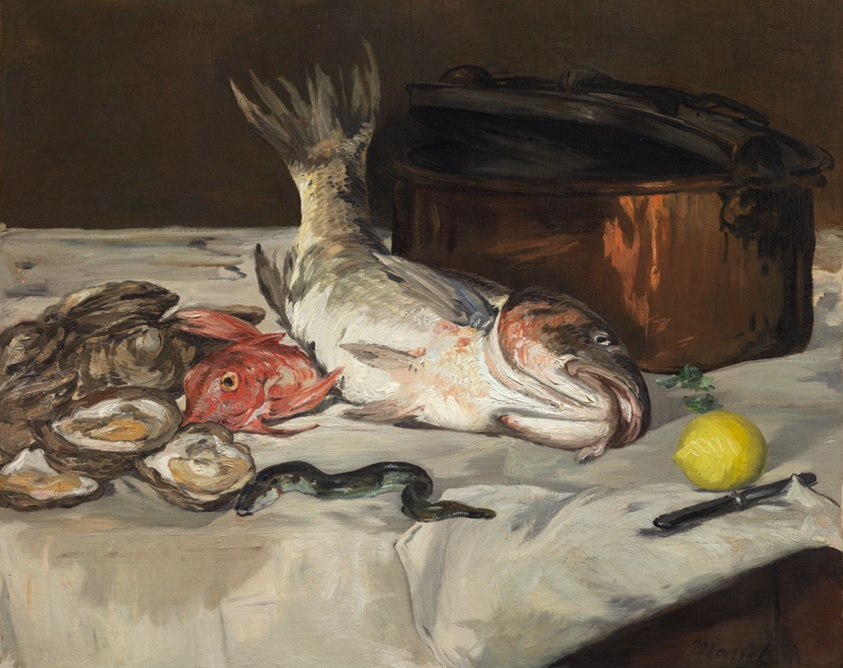

/Users/xiaoyiwen/miniforge3/envs/dfpi/lib/python3.11/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


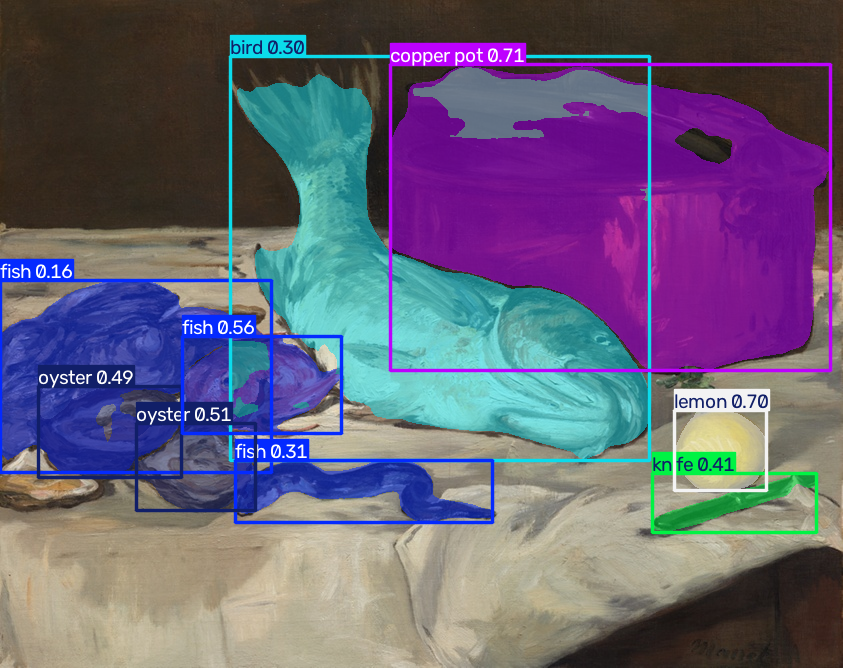

,image_id,title,class_name,confidence,x1,y1,x2,y2
0,aic_44892,Fish (Still Life),copper pot,0.713217,390.949768,64.880737,830.911865,370.928467
1,aic_44892,Fish (Still Life),lemon,0.702738,674.683655,410.515106,766.522705,490.460022
2,aic_44892,Fish (Still Life),fish,0.559181,182.553787,336.583466,341.005096,433.490112
3,aic_44892,Fish (Still Life),oyster,0.507435,136.453842,423.089203,255.223923,510.359009
4,aic_44892,Fish (Still Life),oyster,0.490254,38.638077,386.260223,181.448853,477.404907
5,aic_44892,Fish (Still Life),knife,0.407343,652.284607,473.245697,816.541687,532.483032
6,aic_44892,Fish (Still Life),fish,0.314469,235.594986,460.977112,492.614258,522.074158
7,aic_44892,Fish (Still Life),bird,0.303984,230.848022,56.377674,649.416687,460.103333
8,aic_44892,Fish (Still Life),fish,0.161988,0.000000,280.384247,271.776855,472.204987


Saved detection table: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/outputs/yoloe_detections.csv
Saved 9 YOLOE masks to /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/outputs/yoloe_masks


In [79]:
# STUDENT CHOICE 12: choose an image row from 0 to len(manifest) - 1.
YOLOE_IMAGE_INDEX = 3      # 【改动】Manet《Fish》

# STUDENT CHOICE 13: replace these with 3-10 concrete things relevant to your project.
PROJECT_CLASSES = [        # 【改动】换成静物画里常见、但 COCO 没有的东西
    "fish",
    "bird",
    "lemon",
    "grapes",
    "oyster",
    "flower",
    "bread",
    "jug",
    "knife",
    "copper pot",
]

if manifest.empty:
    raise ValueError("The manifest is empty. Add or download images first.")
if not 0 <= YOLOE_IMAGE_INDEX < len(manifest):
    raise IndexError(f"Choose YOLOE_IMAGE_INDEX between 0 and {len(manifest) - 1}.")

from ultralytics import YOLOE

YOLOE_CHECKPOINT = "yoloe-26s-seg.pt"
yoloe_image_row = manifest.iloc[YOLOE_IMAGE_INDEX]
yoloe_image_path = yoloe_image_row["local_path"]

print("Selected image:", yoloe_image_row["title"])
print("Prompts:", PROJECT_CLASSES)
display(Image.open(yoloe_image_path).convert("RGB"))

# The first call downloads the YOLOE checkpoint and its text encoder.
yoloe_model = YOLOE(YOLOE_CHECKPOINT)
yoloe_model.set_classes(PROJECT_CLASSES)
yoloe_result = yoloe_model.predict(
    yoloe_image_path,
    conf=0.15,
    imgsz=640,
    device=DEVICE,
    retina_masks=True,  # save masks at the original image resolution
    verbose=False,
)[0]

display(Image.fromarray(yoloe_result.plot()[..., ::-1]))

# Turn the detected boxes into a table that can be used in Workshop 3.
yoloe_rows = []
if yoloe_result.boxes is not None:
    boxes = yoloe_result.boxes.xyxy.cpu().numpy()
    confidences = yoloe_result.boxes.conf.cpu().numpy()
    class_ids = yoloe_result.boxes.cls.cpu().numpy().astype(int)

    for box, confidence, class_id in zip(boxes, confidences, class_ids):
        x1, y1, x2, y2 = box.tolist()
        yoloe_rows.append({
            "image_id": yoloe_image_row["id"],
            "title": yoloe_image_row["title"],
            "class_name": yoloe_result.names[class_id],
            "confidence": float(confidence),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),
        })

yoloe_columns = [
    "image_id", "title", "class_name", "confidence",
    "x1", "y1", "x2", "y2",
]
yoloe_detections = pd.DataFrame(yoloe_rows, columns=yoloe_columns)
yoloe_table_path = OUTPUTS_DIR / "yoloe_detections.csv"
yoloe_detections.to_csv(yoloe_table_path, index=False)
display(yoloe_detections)
print("Saved detection table:", yoloe_table_path.resolve())

if yoloe_result.masks is None:
    print("No masks were found. Try simpler nouns, a different image, or conf=0.10.")
else:
    yoloe_masks = yoloe_result.masks.data.cpu().numpy() > 0.5
    yoloe_dir = OUTPUTS_DIR / "yoloe_masks"
    yoloe_dir.mkdir(exist_ok=True)
    for mask_index, mask in enumerate(yoloe_masks):
        mask_path = yoloe_dir / f"{yoloe_image_row['id']}_{mask_index:03d}.png"
        Image.fromarray((mask * 255).astype(np.uint8)).save(mask_path)
    print(f"Saved {len(yoloe_masks)} YOLOE masks to {yoloe_dir.resolve()}")

# SAM

In [80]:
from ultralytics import SAM

# STUDENT CHOICE 7: use sam2.1_b.pt for quality or sam2.1_t.pt for speed.
SAM_CHECKPOINT = "sam2.1_b.pt"
sam_model = SAM(SAM_CHECKPOINT)  # downloads the checkpoint if it is absent

print("SAM checkpoint ready:", SAM_CHECKPOINT)

SAM checkpoint ready: sam2.1_b.pt


Positive point [x, y]: [463, 367]


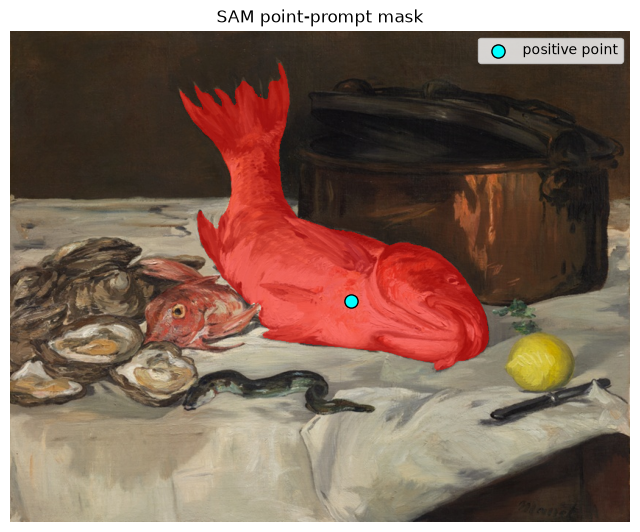

Mask covers 12.4% of the image.
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/outputs/sam_masks/aic_44892_point_mask.png


In [81]:
# STUDENT CHOICE 8: choose the SAM image.
SAM_IMAGE_INDEX = 3            # 【改动】Manet《Fish》
# STUDENT CHOICE 9: move the point by changing these two numbers between 0 and 1.
POINT_X_FRACTION = 0.55        # 【改动】点在大鱼身上
POINT_Y_FRACTION = 0.55        # 【改动】

demo_image_path = manifest.iloc[SAM_IMAGE_INDEX]["local_path"]
with Image.open(demo_image_path) as image:
    image_width, image_height = image.size
    demo_image_rgb = image.convert("RGB")

point_prompt = [
    int(image_width * POINT_X_FRACTION),
    int(image_height * POINT_Y_FRACTION),
]
print("Positive point [x, y]:", point_prompt)

sam_point_result = sam_model(
    demo_image_path,
    points=[point_prompt],
    labels=[1],                 # 1 means include this region
    imgsz=1024,
    device=DEVICE,
    verbose=False,
)[0]

if sam_point_result.masks is None:
    print("No mask was returned. Move the point onto a clearer region and rerun this cell.")
else:
    point_mask = sam_point_result.masks.data[0].cpu().numpy() > 0.5
    point_mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_point_mask.png"
    Image.fromarray((point_mask * 255).astype(np.uint8)).save(point_mask_path)

    plt.figure(figsize=(8, 8))
    plt.imshow(demo_image_rgb)
    plt.imshow(np.ma.masked_where(~point_mask, point_mask), cmap="autumn", alpha=0.55)
    plt.scatter(*point_prompt, s=90, c="cyan", edgecolors="black", label="positive point")
    plt.legend()
    plt.title("SAM point-prompt mask")
    plt.axis("off")
    plt.show()

    print(f"Mask covers {point_mask.mean():.1%} of the image.")
    print("Saved:", point_mask_path.resolve())

# Export

In [82]:
interface_df = manifest_enriched.copy()

# Precompute five neighbours for each item so a simple interface can show "related items".
similarity_matrix = image_embeddings @ image_embeddings.T
neighbour_ids = []
all_ids = manifest["id"].tolist()
for index in range(len(manifest)):
    order = np.argsort(similarity_matrix[index])[::-1]
    order = order[order != index][:5]
    neighbour_ids.append([all_ids[i] for i in order])

interface_df["nearest_ids"] = neighbour_ids

detection_summary = (
    detections.groupby("image_id")["class_name"].apply(list).to_dict()
    if not detections.empty else {}
)
interface_df["detected_objects"] = interface_df["id"].map(
    lambda item_id: detection_summary.get(item_id, [])
)

# Add the project-specific YOLOE labels for the image analysed in Section 5.
yoloe_summary = (
    yoloe_detections.groupby("image_id")["class_name"].apply(list).to_dict()
    if not yoloe_detections.empty else {}
)
interface_df["yoloe_objects"] = interface_df["id"].map(
    lambda item_id: yoloe_summary.get(item_id, [])
)

# Relative paths are easier to move with a future interface project.
interface_df["relative_path"] = interface_df["local_path"].map(
    lambda path: os.path.relpath(path, DATA_DIR)
)

items_path = OUTPUTS_DIR / "items.json"
# Pandas converts NumPy values into standard JSON-compatible Python values.
items = json.loads(interface_df.to_json(orient="records"))
with open(items_path, "w", encoding="utf-8") as file:
    json.dump(items, file, ensure_ascii=False, indent=2)

model_manifest = {
    "clip": CLIP_MODEL_ID,
    "yolo": YOLO_CHECKPOINT,
    "sam": SAM_CHECKPOINT,
    "yoloe": YOLOE_CHECKPOINT,
    "pose_optional": "yolo26n-pose.pt",
    "embedding_shape": list(image_embeddings.shape),
    "notes": "Model outputs require visual inspection and project-specific validation.",
}
model_manifest_path = OUTPUTS_DIR / "model_manifest.json"
with open(model_manifest_path, "w", encoding="utf-8") as file:
    json.dump(model_manifest, file, ensure_ascii=False, indent=2)

manifest_enriched.to_csv(OUTPUTS_DIR / "manifest_enriched.csv", index=False)

print("Interface bundle:")
for path in sorted(OUTPUTS_DIR.iterdir()):
    print(" -", path.name)
print("\nMain interface file:", items_path.resolve())

Interface bundle:
 - .DS_Store
 - clip_image_embeddings.npy
 - detections.csv
 - items.json
 - manifest_enriched.csv
 - model_manifest.json
 - sam_masks
 - yoloe_detections.csv
 - yoloe_masks

Main interface file: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/aic_still_life/outputs/items.json
